# ECR4AD Evaluation Pipeline — Camelyon16-BMAD (CONCH backbone)

Standalone evaluation & reporting notebook for the ECR4AD reproduction.
follows **Section IV (Dataset and Evaluation Metrics)** of the paper:

## Step 1 — Environment Setup & Google Drive Mount

In [1]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-b69f2b76-f22c-180a-079b-6deaaeb1ca5b)


In [2]:
import os, sys

REPO = '/content/wsi_anomaly_detection'
if not os.path.isdir(REPO):
    !git clone --depth 1 --branch main https://github.com/ARHPA/ecr4ad.git {REPO}

os.chdir(REPO)
os.environ['PYTHONPATH'] = os.pathsep.join([REPO, os.path.join(REPO, 'networks')])
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, 'networks'))
print('repo ready:', REPO)

Cloning into '/content/wsi_anomaly_detection'...
remote: Enumerating objects: 322, done.
remote: Counting objects: 100% (322/322), done.
remote: Compressing objects: 100% (228/228), done.
remote: Total 322 (delta 86), reused 318 (delta 83), pack-reused 0 (from 0)
Receiving objects: 100% (322/322), 1.95 MiB | 3.08 MiB/s, done.
Resolving deltas: 100% (86/86), done.
repo ready: /content/wsi_anomaly_detection


In [3]:
!pip -q install timm==0.9.16 transformers huggingface_hub wandb gdown pyyaml scikit-learn scikit-image opencv-python pandas scipy tqdm colorama tabulate einops einops-exts matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 84.3 MB/s eta 0:00:00


In [4]:
from google.colab import userdata

os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
assert os.environ['HF_TOKEN'], 'an HF token is required to download the CONCH weights' 

In [5]:
USE_DRIVE = True
DRIVE_DIR = '/content/drive/MyDrive/wsi_anomaly_detection'
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs(DRIVE_DIR, exist_ok=True)
print('USE_DRIVE =', USE_DRIVE, '| DRIVE_DIR =', DRIVE_DIR)

Mounted at /content/drive
USE_DRIVE = True | DRIVE_DIR = /content/drive/MyDrive/wsi_anomaly_detection


In [7]:
import glob

HISTO_ZIP_ID = '1pXbfOgESrGhqZHaf2LGriH6TEG17uDDN'  # Histopathology_AD.zip (Camelyon16-BMAD)

def detect_data_root():
    """Return the directory that CONTAINS train/, valid/, test/ """
    for base in ('/content/dataset', '/content/gdrive_dataset'):
        if not os.path.isdir(base):
            continue
        for root, dirs, files in os.walk(base):
            if 'train' in dirs and 'test' in dirs and os.path.isdir(os.path.join(root, 'train', 'good')):
                return root
    return None

DATA_ROOT = detect_data_root()
if DATA_ROOT is None:
    zips = glob.glob('/content/**/Histopathology_AD.zip', recursive=True)
    if not zips:
        print('Histopathology_AD.zip not found -> downloading it ...')
        os.makedirs('/content/dataset', exist_ok=True)
        !gdown {HISTO_ZIP_ID} -O /content/dataset/Histopathology_AD.zip
        zips = glob.glob('/content/**/Histopathology_AD.zip', recursive=True)
    os.makedirs('/content/dataset', exist_ok=True)
    print('Extracting', zips[0], '-> /content/dataset')
    !unzip -q -o '{zips[0]}' -d /content/dataset
    DATA_ROOT = detect_data_root()

def _n(split, *parts):
    return len(glob.glob(os.path.join(DATA_ROOT, split, *parts, '*.png')))

counts = {
    'train/good': _n('train', 'good'),
    'valid/good': _n('valid', 'good', 'img') or _n('valid', 'good'),
    'valid/Ungood': _n('valid', 'Ungood', 'img') or _n('valid', 'Ungood'),
    'test/good': _n('test', 'good', 'img') or _n('test', 'good'),
    'test/Ungood': _n('test', 'Ungood', 'img') or _n('test', 'Ungood'),
}
for k, v in counts.items():
    print(f'{k:16s} {v}')
print('DATA_ROOT =', DATA_ROOT)

train/good       5088
valid/good       117
valid/Ungood     119
test/good        1003
test/Ungood      994
DATA_ROOT = /content/dataset/camelyon16_256


In [8]:
from google.colab import userdata
from huggingface_hub import login, hf_hub_download

login(token=userdata.get('HF_TOKEN'))
os.environ.setdefault('WEIGHTS_DIR', '/content/weights')
os.makedirs(os.environ['WEIGHTS_DIR'], exist_ok=True)
os.environ['CONCH_CKPT'] = hf_hub_download(
    repo_id='MahmoodLab/conch', filename='pytorch_model.bin',
    cache_dir=os.environ['WEIGHTS_DIR'])
assert os.path.isfile(os.environ['CONCH_CKPT']), 'CONCH checkpoint download failed'
print('CONCH_CKPT =', os.environ['CONCH_CKPT'])

In [9]:
import random
import numpy as np
import torch

SEED = 1
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda')
print('seed:', SEED, '| device:', torch.cuda.get_device_name(0))

OUT_DIR = os.path.join(REPO, 'outputs')
OUT_FIGS = os.path.join(OUT_DIR, 'evaluation_figures')
os.makedirs(OUT_FIGS, exist_ok=True)
print('figures ->', OUT_FIGS)

seed: 1 | device: Tesla T4
figures -> /content/wsi_anomaly_detection/outputs/evaluation_figures


## Step 2 — Model & Checkpoint Loading

In [14]:
import yaml, torch, torch.nn as nn
from functools import partial

CONFIG = os.path.join(REPO, 'configs', 'conch', 'conch_bmad_config_ecr4ad.yaml')
cfg = {k: v['value'] for k, v in yaml.safe_load(open(CONFIG, encoding='utf-8')).items()}

if not (cfg.get('data_root') and os.path.isdir(cfg['data_root'])):
    cfg['data_root'] = DATA_ROOT
SAVE_PATH = DRIVE_DIR if USE_DRIVE else '/content/results'
if not cfg.get('save_path'):
    cfg['save_path'] = SAVE_PATH
os.makedirs(os.path.join(cfg['save_path'], 'weights'), exist_ok=True)

wdir = os.path.join(cfg['save_path'], 'weights')
best = sorted(glob.glob(os.path.join(wdir, '*_best_model_patch_train.pth')))
last = sorted(glob.glob(os.path.join(wdir, '*_last_patch_train.pth')))

CKPT = best[-1] if best else last[-1]
state = torch.load(CKPT, map_location='cpu', weights_only=True)
if isinstance(state, dict) and 'model' in state:  
    state = state['model']
    CKPT_KIND = 'last (resume checkpoint) -> weights only'
else:
    CKPT_KIND = 'best (plain state_dict)'
print('checkpoint :', CKPT)
print('kind       :', CKPT_KIND)
print('config     :', {k: cfg[k] for k in ('backbone', 'dataset', 'image_size',
                                           'target_layers', 'attn_method', 'num_heads', 'fuse_layers')})

checkpoint : /content/drive/MyDrive/wsi_anomaly_detection/weights/Camelyon16BMAD_conch_best_model_patch_train.pth
kind       : best (plain state_dict)
config     : {'backbone': 'conch', 'dataset': 'Camelyon16BMAD', 'image_size': 224, 'target_layers': [8, 9, 10, 11], 'attn_method': 'qkv_attn', 'num_heads': 1, 'fuse_layers': [[0], [1], [2], [3]]}


In [15]:
from networks import vit_encoder
from networks.vision_transformer import Block as VitBlock, bMlp, Attention, LinearAttention2, FeatureJitter
from models.conch_conditional_uad import ViTill

embed_dim = 768  # CONCH ViT-B/16

encoder = vit_encoder.load(cfg['backbone'])
for p in encoder.parameters():
    p.requires_grad = False
n_enc = sum(p.numel() for p in encoder.parameters())

attention_func = LinearAttention2 if cfg['attn_method'] == 'linear_attn' else Attention
if cfg.get('feature_jitter'):
    bottleneck = [nn.Sequential(FeatureJitter(scale=20),
                                bMlp(embed_dim, embed_dim * 4, embed_dim, drop=cfg['bottleneck_dropout']))]
else:
    bottleneck = [bMlp(embed_dim, embed_dim * 4, embed_dim, drop=cfg['bottleneck_dropout'])]
bottleneck = nn.ModuleList(bottleneck)

decoder = nn.ModuleList([
    VitBlock(dim=embed_dim, num_heads=cfg['num_heads'], mlp_ratio=4., qkv_bias=True,
             norm_layer=partial(nn.LayerNorm, eps=1e-8), attn=attention_func)
    for _ in cfg['target_layers']])

model = ViTill(
    encoder=encoder, bottleneck=bottleneck, decoder=decoder,
    target_layers=cfg['target_layers'],
    mask_neighbor_size=cfg['mask_neighbor_size'],
    fuse_layer_encoder=cfg['fuse_layers'], fuse_layer_decoder=cfg['fuse_layers'],
    encoder_require_grad_layer=[], remove_class_token=cfg['remove_class_token'],
    bottleneck_fusion=cfg['bottleneck_fusion'], embed_dim=embed_dim)
model = model.to(device)
model.load_state_dict(state, strict=True)
model.eval()

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'params: total {n_total:,} | trainable (bottleneck+decoder) {n_train:,} | frozen encoder {n_enc:,}')
print('model in eval mode, weights <-', CKPT)

/content/wsi_anomaly_detection/networks/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/content/wsi_anomaly_detection/networks/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/content/wsi_anomaly_detection/networks/dinov2/layers/block.py:39: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


params: total 154,948,608 | trainable (bottleneck+decoder) 64,555,776 | frozen encoder 395,232,769
model in eval mode, weights <- /content/drive/MyDrive/wsi_anomaly_detection/weights/Camelyon16BMAD_conch_best_model_patch_train.pth


## Step 3 — Dataloaders

In [16]:
from torch.utils.data import DataLoader, Subset
from dataloader.camelyon16_bmad import Camelyon16BMAD

test_set = Camelyon16BMAD(data_root=cfg['data_root'], setname='test', image_size=cfg['image_size'])
val_set = Camelyon16BMAD(data_root=cfg['data_root'], setname='valid', image_size=cfg['image_size'])

CALIB_SOURCE = 'valid'
if len(val_set) == 0:
    CALIB_SOURCE = 'train'
    val_set = Camelyon16BMAD(data_root=cfg['data_root'], setname='train', image_size=cfg['image_size'])

val_loader = DataLoader(val_set, batch_size=128, num_workers=2, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=128, num_workers=2, shuffle=False, pin_memory=True)
print(f'calibration set ({CALIB_SOURCE}): {len(val_set)} patches')
print(f'test set                    : {len(test_set)} patches')

calibration set (valid): 236 patches
test set                    : 1997 patches


/content/wsi_anomaly_detection/dataloader/__init__.py:15: UserWarning: Whole-slide utilities (openslide/pyvips) are unavailable: No module named 'openslide'. Patch-level datasets (e.g. Camelyon16BMAD) will still work.
  warnings.warn(


## Step 4 — Validation Set Calibration


In [22]:
import numpy as np
from tqdm import tqdm
from utils import cal_anomaly_maps, get_gaussian_kernel

MAX_RATIO = 0.01  
GAUSS = get_gaussian_kernel(kernel_size=5, sigma=4).to(device)

@torch.no_grad()
def collect_scores(model, loader, desc='infer'):
    model.eval()
    scores, labels, paths = [], [], []
    for img, label, fname in tqdm(loader, desc=desc):
        img = img.to(device, non_blocking=True)
        en, de = model(img)
        amap, _ = cal_anomaly_maps(en, de, img.shape[-1])   
        amap = GAUSS(amap).flatten(1)                       
        k = max(1, int(amap.shape[1] * MAX_RATIO))
        topk = torch.sort(amap, dim=1, descending=True)[0][:, :k]
        scores.append(topk.mean(dim=1).float().cpu())
        labels.append(label if torch.is_tensor(label) else torch.as_tensor(label))
        paths.extend(list(fname))
    return (torch.cat(scores).numpy(),
            torch.cat(labels).numpy().astype(int),
            paths)

calibration (valid): 100%|██████████| 2/2 [00:05<00:00,  2.71s/it]


T95 = 0.047814   |   95th percentile of 117 normal valid scores (119 tumor patches excluded)


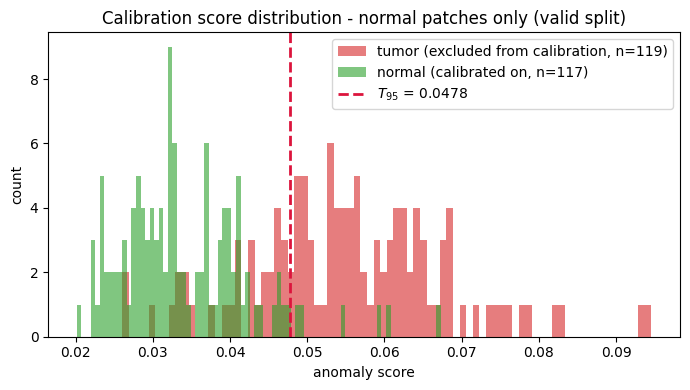

In [23]:
import matplotlib.pyplot as plt

val_scores, val_labels, _ = collect_scores(model, val_loader,
                                           desc=f'calibration ({CALIB_SOURCE})')
val_normal_scores = val_scores[val_labels == 0]
T95 = float(np.percentile(val_normal_scores, 95))
n_val_normal = int(val_normal_scores.size)
n_val_tumor = int(val_scores.size - n_val_normal)
print(f'T95 = {T95:.6f}   |   95th percentile of {n_val_normal} normal {CALIB_SOURCE} scores '
      f'({n_val_tumor} tumor patches excluded)')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(val_scores[val_labels == 1], bins=80, alpha=0.6, color='tab:red',
        label=f'tumor (excluded from calibration, n={n_val_tumor})')
ax.hist(val_normal_scores, bins=80, alpha=0.6, color='tab:green',
        label=f'normal (calibrated on, n={n_val_normal})')
ax.axvline(T95, color='crimson', ls='--', lw=2, label=f'$T_{{95}}$ = {T95:.4f}')
ax.set_xlabel('anomaly score')
ax.set_ylabel('count')
ax.set_title(f'Calibration score distribution - normal patches only ({CALIB_SOURCE} split)')
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUT_FIGS, '01_calibration_T95.png'), dpi=200)
plt.show()

## Step 5 — Test Set Inference & Quantitative Metrics

In [24]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
                           precision_recall_curve, confusion_matrix)

test_scores, test_labels, test_paths = collect_scores(model, test_loader, desc='test inference')
n_pos = int(test_labels.sum())
n_neg = len(test_labels) - n_pos
print(f'test patches: {len(test_labels)}  (normal={n_neg}, tumor={n_pos})')

# --- threshold-free metrics ---
auroc = float(roc_auc_score(test_labels, test_scores))
ap = float(average_precision_score(test_labels, test_scores))
prec, rec, _ = precision_recall_curve(test_labels, test_scores)
f1_curve = np.divide(2 * prec * rec, prec + rec,
                     out=np.zeros_like(prec), where=(prec + rec) > 0)
f1_max = float(f1_curve.max())

# --- deterministic metrics strictly at T95 ---
pred95 = (test_scores >= T95).astype(int)
tn, fp, fn, tp = confusion_matrix(test_labels, pred95, labels=[0, 1]).ravel()
tpr = float(tp / (tp + fn)) if (tp + fn) else 0.0   
fpr = float(fp / (fp + tn)) if (fp + tn) else 0.0   

PAPER_AUROC = 0.9462  # ECR4AD reported tile-level AUROC
print(f'AUROC={auroc:.4f}  AP={ap:.4f}  F1-max={f1_max:.4f}  '
      f'TPR@T95={tpr:.4f}  FPR@T95={fpr:.4f}')
print(f'confusion @T95: TP={tp} FP={fp} TN={tn} FN={fn}')

test inference: 100%|██████████| 16/16 [00:29<00:00,  1.85s/it]

test patches: 1997  (normal=1003, tumor=994)
AUROC=0.9453  AP=0.9368  F1-max=0.8764  TPR@T95=0.8109  FPR@T95=0.0778
confusion @T95: TP=806 FP=78 TN=925 FN=188


In [29]:
from IPython.display import Markdown, display

# Paper reference values
PAPER_METRICS = {
    'AUROC': 0.9462,
    'AP': 0.9372,
    'F1_MAX': 0.8772,
    'TPR': None,
    'FPR': None,
}

def pct(x):
    return f'{100 * x:.2f} %' if x is not None else '-'

def delta(rep, paper):
    if rep is None or paper is None:
        return '-'
    d = 100 * (rep - paper)
    return f'{d:+.2f} pp'

rows = [
    ('AUROC (tile-level)', pct(auroc), pct(PAPER_METRICS['AUROC']), delta(auroc, PAPER_METRICS['AUROC'])),
    ('Average Precision (AP)', pct(ap), pct(PAPER_METRICS['AP']), delta(ap, PAPER_METRICS['AP'])),
    ('F1-max', pct(f1_max), pct(PAPER_METRICS['F1_MAX']), delta(f1_max, PAPER_METRICS['F1_MAX'])),
    ('TPR / Sensitivity @ $T_{95}$', pct(tpr), pct(PAPER_METRICS['TPR']), delta(tpr, PAPER_METRICS['TPR'])),
    ('FPR (1 - Specificity) @ $T_{95}$', pct(fpr), pct(PAPER_METRICS['FPR']), delta(fpr, PAPER_METRICS['FPR'])),
]

table = '\n'.join(f'| {a} | {b} | {c} | {d} |' for a, b, c, d in rows)

display(Markdown(
    '### ECR4AD reproduction vs. paper (Section IV)\n\n'
    f'Threshold for TPR/FPR: **$T_{{95}}$ = {T95:.6f}** '
    f'(95th percentile of **normal {CALIB_SOURCE}** anomaly scores) &nbsp;|&nbsp; '
    f'confusion matrix: TP={tp}, FP={fp}, TN={tn}, FN={fn}\n\n'
    '| Metric | ECR4AD reproduction | Paper target | delta |\n'
    '|---|---|---|---|\n'
    + table + '\n\n'))

### ECR4AD reproduction vs. paper (Section IV)

Threshold for TPR/FPR: **$T_{95}$ = 0.047814** (95th percentile of **normal valid** anomaly scores) &nbsp;|&nbsp; confusion matrix: TP=806, FP=78, TN=925, FN=188

| Metric | ECR4AD reproduction | Paper target | delta |
|---|---|---|---|
| AUROC (tile-level) | 94.53 % | 94.62 % | -0.09 pp |
| Average Precision (AP) | 93.68 % | 93.72 % | -0.04 pp |
| F1-max | 87.64 % | 87.72 % | -0.08 pp |
| TPR / Sensitivity @ $T_{95}$ | 81.09 % | - | - |
| FPR (1 - Specificity) @ $T_{95}$ | 7.78 % | - | - |



## Step 6 — Curves & Statistical Plots

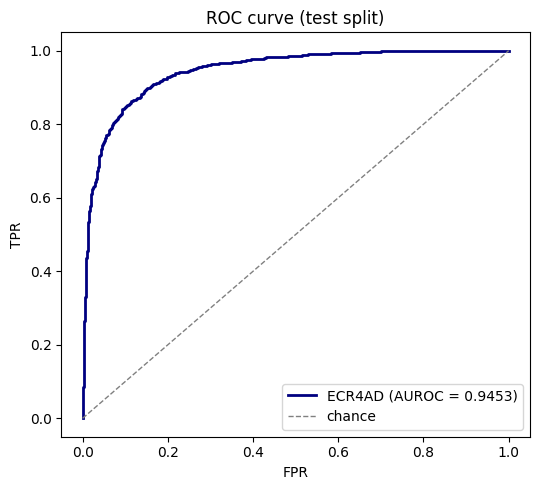

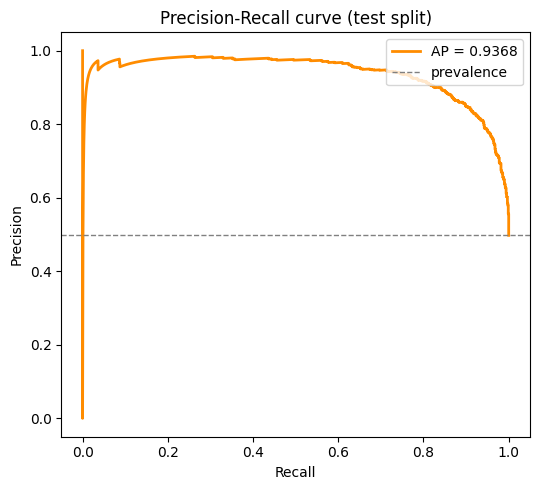

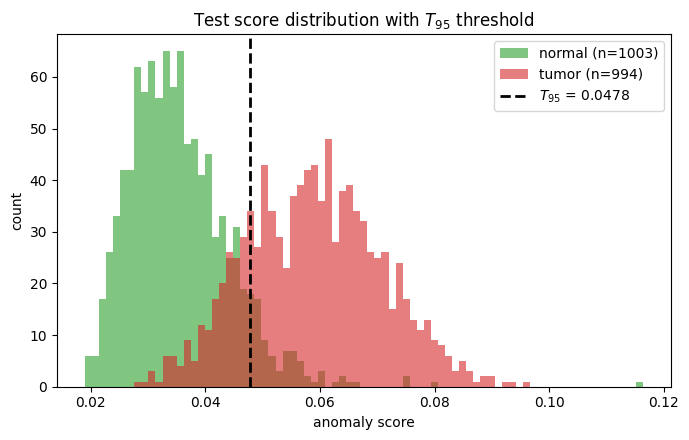

In [30]:
from sklearn.metrics import roc_curve

# (1) ROC curve
fpr_r, tpr_r, _ = roc_curve(test_labels, test_scores)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr_r, tpr_r, lw=2, color='navy', label=f'ECR4AD (AUROC = {auroc:.4f})')
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='chance')
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')
ax.set_title('ROC curve (test split)')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(os.path.join(OUT_FIGS, '02_roc_curve.png'), dpi=200)
plt.show()

# (2) Precision-Recall curve
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(rec, prec, lw=2, color='darkorange', label=f'AP = {ap:.4f}')
ax.axhline(n_pos / len(test_labels), ls='--', color='grey', lw=1, label='prevalence')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curve (test split)')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(os.path.join(OUT_FIGS, '03_pr_curve.png'), dpi=200)
plt.show()

# (3) Score distribution by class + T95
lo = min(float(test_scores.min()), T95)
hi = float(test_scores.max())
if hi <= lo:
    hi = lo + 1e-6
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(lo, hi, 80)
ax.hist(test_scores[test_labels == 0], bins=bins, alpha=0.6, color='tab:green',
        label=f'normal (n={n_neg})')
ax.hist(test_scores[test_labels == 1], bins=bins, alpha=0.6, color='tab:red',
        label=f'tumor (n={n_pos})')
ax.axvline(T95, color='k', ls='--', lw=2, label=f'$T_{{95}}$ = {T95:.4f}')
ax.set_xlabel('anomaly score')
ax.set_ylabel('count')
ax.set_title('Test score distribution with $T_{95}$ threshold')
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUT_FIGS, '04_test_score_distribution.png'), dpi=200)
plt.show()

## Step 7 — Qualitative Visualization & Failure Analysis (Heatmaps)


In [31]:
from utils import min_max_norm, cvt2heatmap

MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def overlay(img_t, amap):
    im = img_t.permute(1, 2, 0).cpu().numpy() * STD + MEAN
    im = np.clip(im * 255, 0, 255).astype(np.uint8)
    hm = min_max_norm(amap) * 255.0
    hm_rgb = cvt2heatmap(hm)[:, :, ::-1]             
    cam = np.float32(hm_rgb) / 255 + np.float32(im) / 255
    cam = cam / (np.max(cam) + 1e-8)
    return np.uint8(255 * cam), im

groups = [
    ('TP', (pred95 == 1) & (test_labels == 1)),
    ('TN', (pred95 == 0) & (test_labels == 0)),
    ('FP', (pred95 == 1) & (test_labels == 0)),
    ('FN', (pred95 == 0) & (test_labels == 1)),
]
K = 3  
selected, group_slices = [], {}
for gname, gmask in groups:
    idx = np.where(gmask)[0][:K]
    group_slices[gname] = (len(selected), len(selected) + len(idx))
    selected.extend(idx.tolist())

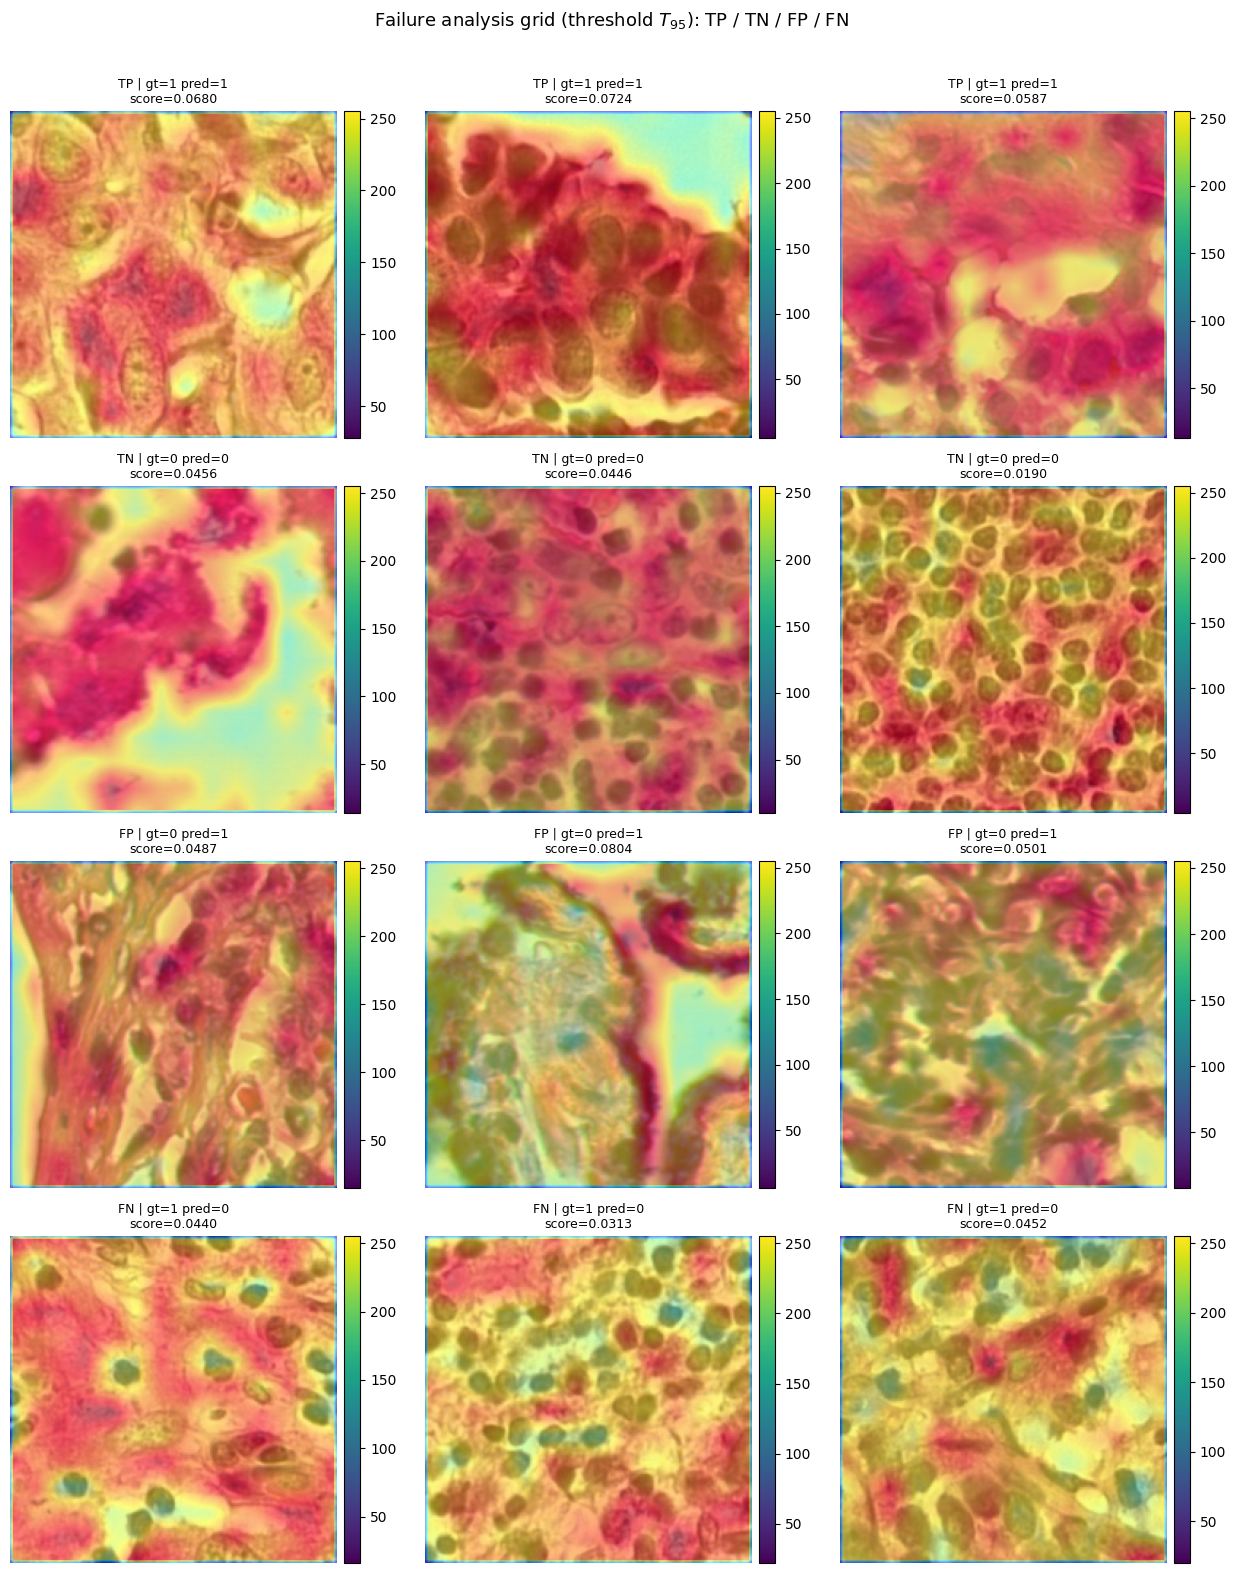

group sizes: {'TP': 806, 'TN': 925, 'FP': 78, 'FN': 188}


In [32]:
sub_loader = DataLoader(Subset(test_set, selected), batch_size=max(len(selected), 1),
                        num_workers=0, shuffle=False)
images, maps = [], []
model.eval()
with torch.no_grad():
    for img, _, _ in sub_loader:
        img = img.to(device)
        en, de = model(img)
        amap, _ = cal_anomaly_maps(en, de, img.shape[-1])
        amap = GAUSS(amap)[:, 0].cpu().numpy()          # (B, H, W)
        images.extend([img[i].cpu() for i in range(img.shape[0])])
        maps.extend(amap)

fig, axes = plt.subplots(4, K, figsize=(4.2 * K, 4.0 * 4), squeeze=False)
for r, (gname, gmask) in enumerate(groups):
    start, end = group_slices[gname]
    for c in range(K):
        ax = axes[r][c]
        ax.axis('off')
        if start + c < end:
            gi = start + c
            ti = selected[gi]
            cam_rgb, _ = overlay(images[gi], maps[gi])
            im = ax.imshow(cam_rgb)
            ax.set_title(f'{gname} | gt={test_labels[ti]} pred={pred95[ti]}\n'
                         f'score={test_scores[ti]:.4f}', fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        else:
            ax.text(0.5, 0.5, 'no samples', ha='center', va='center',
                    transform=ax.transAxes, color='grey')
    axes[r][0].set_ylabel(gname, fontsize=13)
fig.suptitle('Failure analysis grid (threshold $T_{95}$): TP / TN / FP / FN', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(os.path.join(OUT_FIGS, '05_failure_analysis_grid.png'), dpi=200)
plt.show()
print('group sizes:', {g: int(m.sum()) for g, m in groups})

## Step 8 — Export Results

Writes `outputs/results.json`, `outputs/metrics_summary.csv`, and all figures under
`outputs/evaluation_figures/`; 

In [33]:
import csv, json, shutil

results = {
    'dataset': 'Camelyon16-BMAD',
    'backbone': cfg['backbone'],
    'checkpoint': CKPT,
    'checkpoint_kind': CKPT_KIND,
    'config_file': CONFIG,
    'repo_commit': REPO_SHA[0],
    'calibration_split': CALIB_SOURCE,
    'calibration_normal_only': True,
    'threshold_t95': T95,
    'metrics': {
        'auroc': auroc,
        'ap': ap,
        'f1_max': f1_max,
        'tpr_at_t95': tpr,
        'fpr_at_t95': fpr,
    },
    'confusion_t95': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
    'counts': {'test': int(len(test_labels)), 'normal': int(n_neg),
               'tumor': int(n_pos), 'calibration_total': int(len(val_scores)),
               'calibration_normal': int(len(val_normal_scores))},
    'paper_target_auroc': PAPER_AUROC,
    'delta_auroc_pp': 100.0 * (auroc - PAPER_AUROC),
}
json_path = os.path.join(OUT_DIR, 'results.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(results, f, indent=2)

csv_path = os.path.join(OUT_DIR, 'metrics_summary.csv')
with open(csv_path, 'w', newline='', encoding='utf-8') as f:
    w = csv.writer(f)
    w.writerow(['dataset', 'backbone', 'checkpoint', 'calib_split', 'threshold_t95',
                'auroc', 'ap', 'f1_max', 'tpr_at_t95', 'fpr_at_t95',
                'tn', 'fp', 'fn', 'tp', 'n_test', 'paper_auroc', 'delta_pp'])
    w.writerow(['Camelyon16-BMAD', cfg['backbone'], CKPT, f'{CALIB_SOURCE}-normal', f'{T95:.6f}',
                f'{auroc:.6f}', f'{ap:.6f}', f'{f1_max:.6f}', f'{tpr:.6f}', f'{fpr:.6f}',
                tn, fp, fn, tp, len(test_labels), PAPER_AUROC,
                f'{100.0 * (auroc - PAPER_AUROC):+.2f}'])
print('wrote', json_path)
print('wrote', csv_path)

if USE_DRIVE:
    dst = os.path.join(DRIVE_DIR, 'outputs')
    shutil.copytree(OUT_DIR, dst, dirs_exist_ok=True)
    print('mirrored to', dst)

display(Markdown('**Evaluation complete.** Figures: `outputs/evaluation_figures/` | '
                 'Metrics: `results.json`, `metrics_summary.csv`'))

wrote /content/wsi_anomaly_detection/outputs/results.json
wrote /content/wsi_anomaly_detection/outputs/metrics_summary.csv
mirrored to /content/drive/MyDrive/wsi_anomaly_detection/outputs


**Evaluation complete.** Figures: `outputs/evaluation_figures/` | Metrics: `results.json`, `metrics_summary.csv`